In [1]:
 
# 1. Import Libraries
 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
 
# 2. Set Random Seed
 
SEED = 42
 
# 3. Define Features
 
FEATURE_COLS = [
    "Age",
    "Weight_kg",
    "Height_m",
    "Max_BPM",
    "Avg_BPM",
    "Resting_BPM",
    "Session_Duration_min",
    "Fat_Percentage",
    "Water_Intake_liters",
    "BMI"
]
 
# 4. Load Dataset
 
df = pd.read_csv("../backend/data/gym_members_clean.csv")
 
# 5. Split Features and Targets
 
Xtr, Xte, yc_tr, yc_te, yr_tr, yr_te = train_test_split(
    df[FEATURE_COLS],
    df["Overtraining_Risk_Label"],
    df["Calories_Burned"],
    test_size=0.2,
    random_state=SEED,
    stratify=df["Overtraining_Risk_Label"]
)
 
# 6. Display Basic Information
 
print("Libraries imported successfully!")
print("Dataset shape:", df.shape)
print("Training shape:", Xtr.shape)
print("Testing shape:", Xte.shape)
print("\nDataset loaded and split successfully!")

Libraries imported successfully!
Dataset shape: (973, 14)
Training shape: (778, 10)
Testing shape: (195, 10)

Dataset loaded and split successfully!


In [2]:
# Stage 1: Exploratory Data Analysis (EDA)
 
# 1. Dataset Information
print("Dataset Shape:")
print(df.shape)
 
print("\nDataset Columns:")
print(df.columns.tolist())
 
print("\nDataset Information:")
df.info()
 
# 2. Statistical Summary
print("\nStatistical Summary:")
display(df.describe())
 
# 3. Check Missing Values
print("\nMissing Values:")
display(df.isnull().sum())
 
# 4. Check Duplicate Rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Shape:
(973, 14)

Dataset Columns:
['Age', 'Weight_kg', 'Height_m', 'Max_BPM', 'Avg_BPM', 'Resting_BPM', 'Session_Duration_min', 'Fat_Percentage', 'Water_Intake_liters', 'BMI', 'Workout_Type', 'Experience_Level', 'Calories_Burned', 'Overtraining_Risk_Label']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 973 entries, 0 to 972
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      973 non-null    float64
 1   Weight_kg                973 non-null    float64
 2   Height_m                 973 non-null    float64
 3   Max_BPM                  973 non-null    float64
 4   Avg_BPM                  973 non-null    float64
 5   Resting_BPM              973 non-null    float64
 6   Session_Duration_min     973 non-null    float64
 7   Fat_Percentage           973 non-null    float64
 8   Water_Intake_liters      973 non-null    float64
 9   BMI               

,Age,Weight_kg,Height_m,Max_BPM,Avg_BPM,Resting_BPM,Session_Duration_min,Fat_Percentage,Water_Intake_liters,BMI,Experience_Level,Calories_Burned,Overtraining_Risk_Label
count,973.000000,973.000000,973.00000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000
mean,38.683453,73.854676,1.72258,179.883864,143.766701,62.223022,75.385406,24.976773,2.626619,24.912127,1.809866,905.422405,0.650565
std,12.180928,21.207500,0.12772,11.525686,14.345101,7.327060,20.582009,6.259419,0.600172,6.660879,0.739693,272.641516,0.477037
min,18.000000,40.000000,1.50000,160.000000,120.000000,50.000000,30.000000,10.000000,1.500000,12.320000,1.000000,303.000000,0.000000
25%,28.000000,58.100000,1.62000,170.000000,131.000000,56.000000,62.400000,21.300000,2.200000,20.110000,1.000000,720.000000,0.000000
50%,40.000000,70.000000,1.71000,180.000000,143.000000,62.000000,75.600000,26.200000,2.600000,24.160000,2.000000,893.000000,1.000000
75%,49.000000,86.000000,1.80000,190.000000,156.000000,68.000000,87.600000,29.300000,3.100000,28.560000,2.000000,1076.000000,1.000000
max,59.000000,129.900000,2.00000,199.000000,169.000000,74.000000,120.000000,35.000000,3.700000,49.840000,3.000000,1783.000000,1.000000



Missing Values:


Age                        0
Weight_kg                  0
Height_m                   0
Max_BPM                    0
Avg_BPM                    0
Resting_BPM                0
Session_Duration_min       0
Fat_Percentage             0
Water_Intake_liters        0
BMI                        0
Workout_Type               0
Experience_Level           0
Calories_Burned            0
Overtraining_Risk_Label    0
dtype: int64


Duplicate Rows:
0


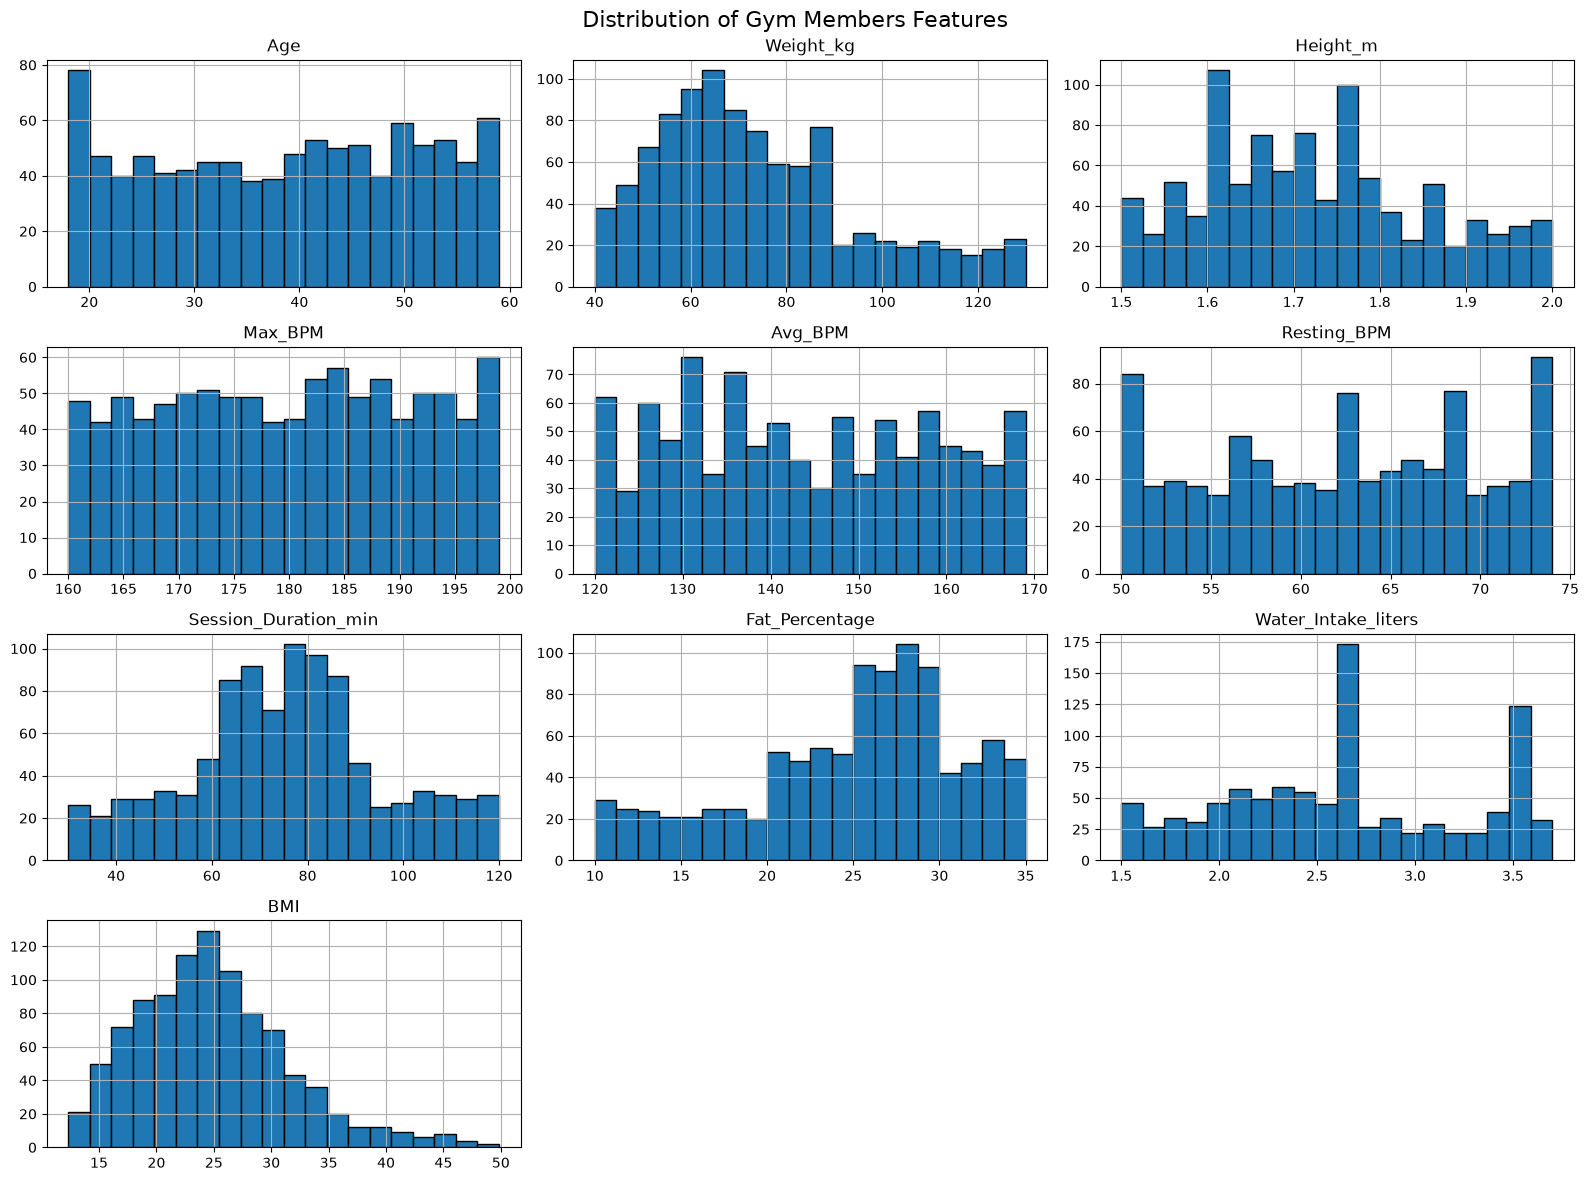

In [3]:
# Stage 1: Feature Distributions (Histograms)
 
df[FEATURE_COLS].hist(
    figsize=(16, 12),
    bins=20,
    edgecolor="black"
)
 
plt.suptitle("Distribution of Gym Members Features", fontsize=16)
plt.tight_layout()
plt.show()

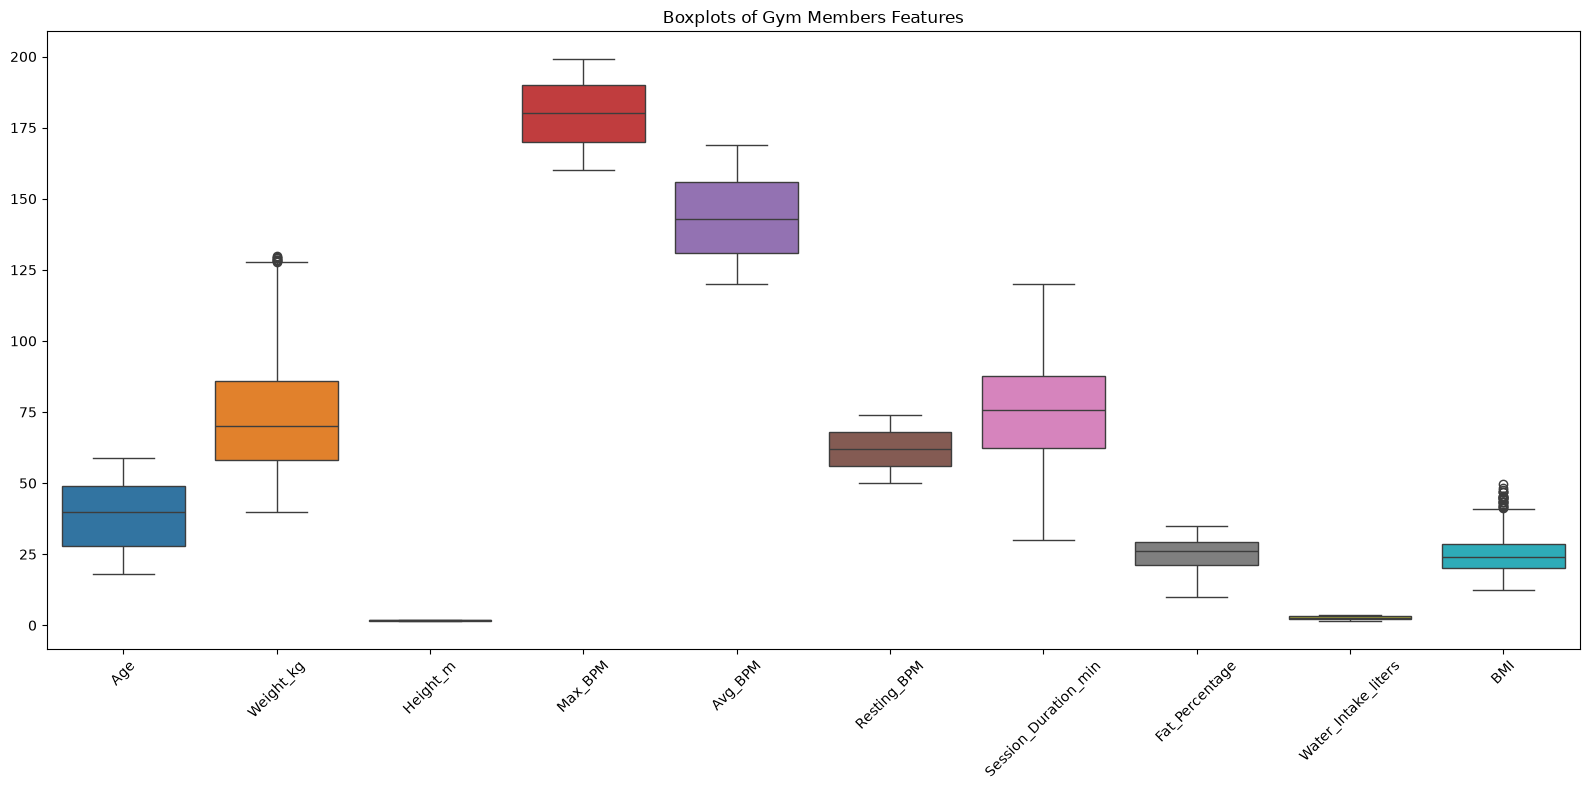

In [4]:
# Stage 1: Boxplots for Outlier Detection
 
plt.figure(figsize=(16, 8))
 
sns.boxplot(data=df[FEATURE_COLS])
 
plt.title("Boxplots of Gym Members Features")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

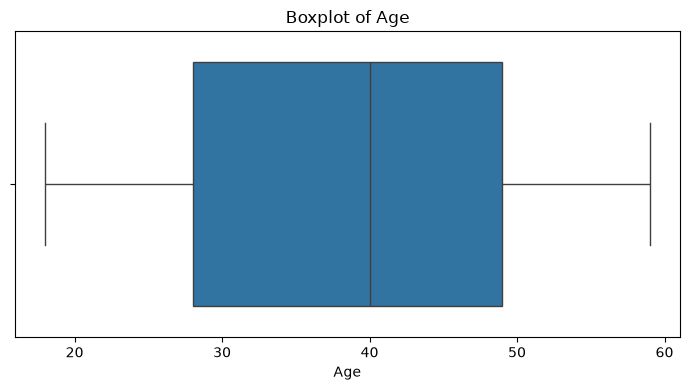

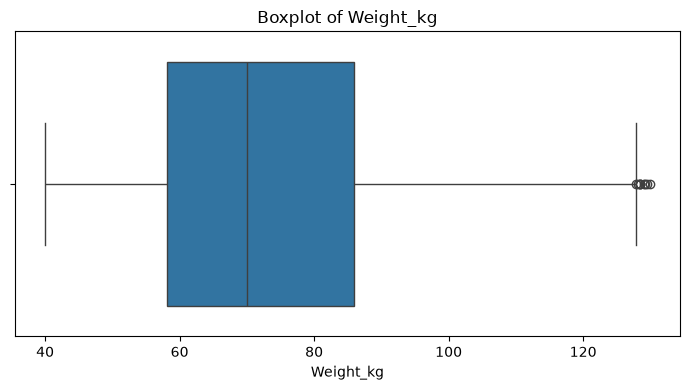

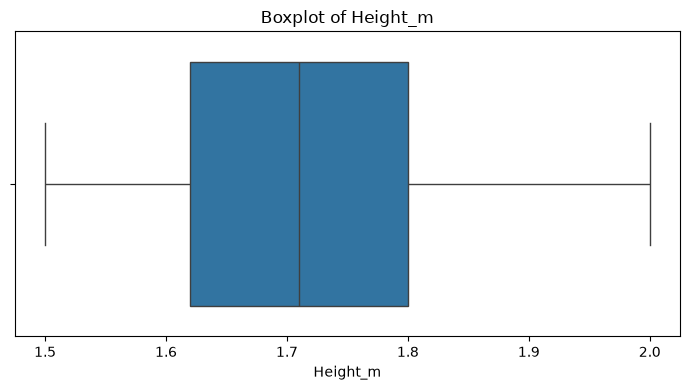

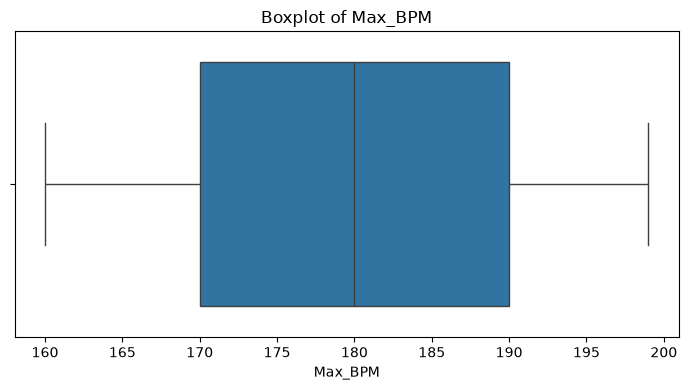

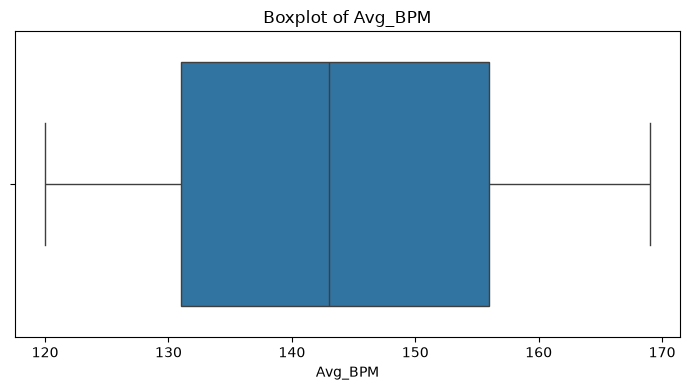

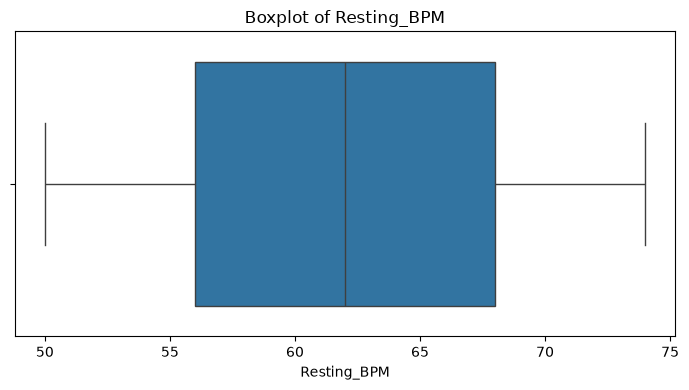

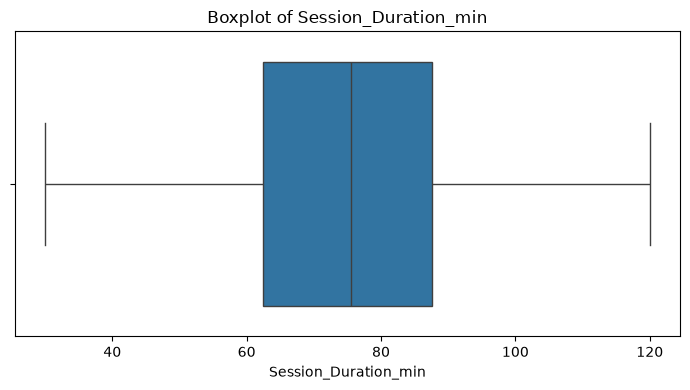

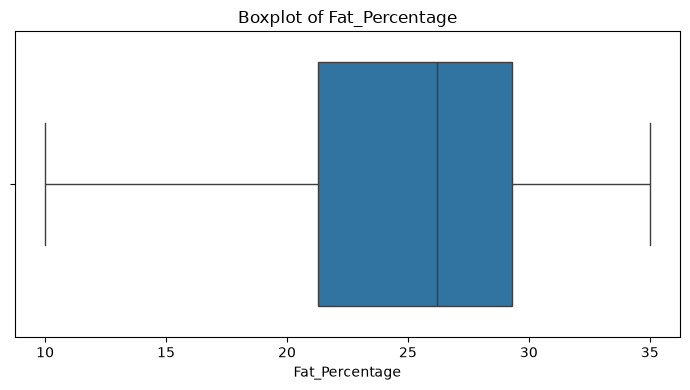

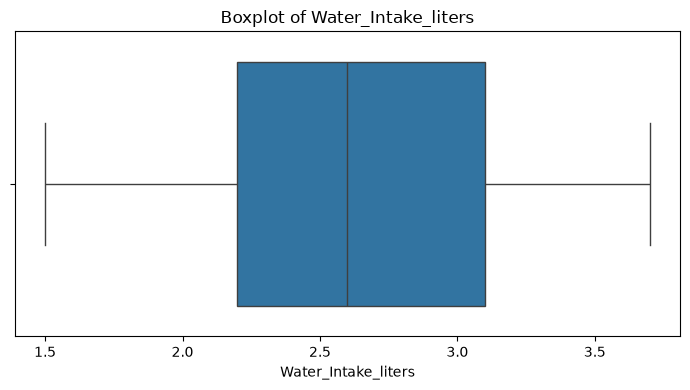

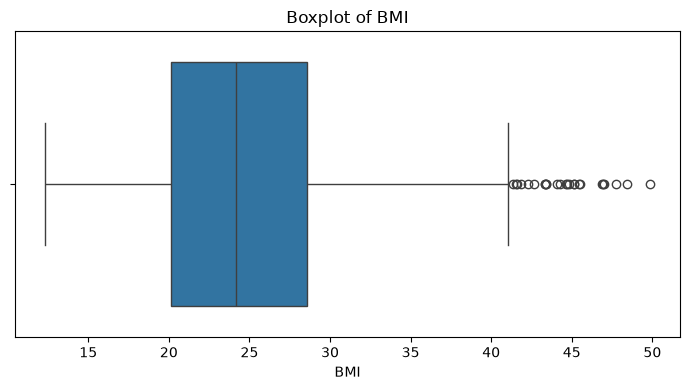

In [5]:
# Individual Boxplots for Each Feature
 
for col in FEATURE_COLS:
    plt.figure(figsize=(7, 4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.tight_layout()
    plt.show()

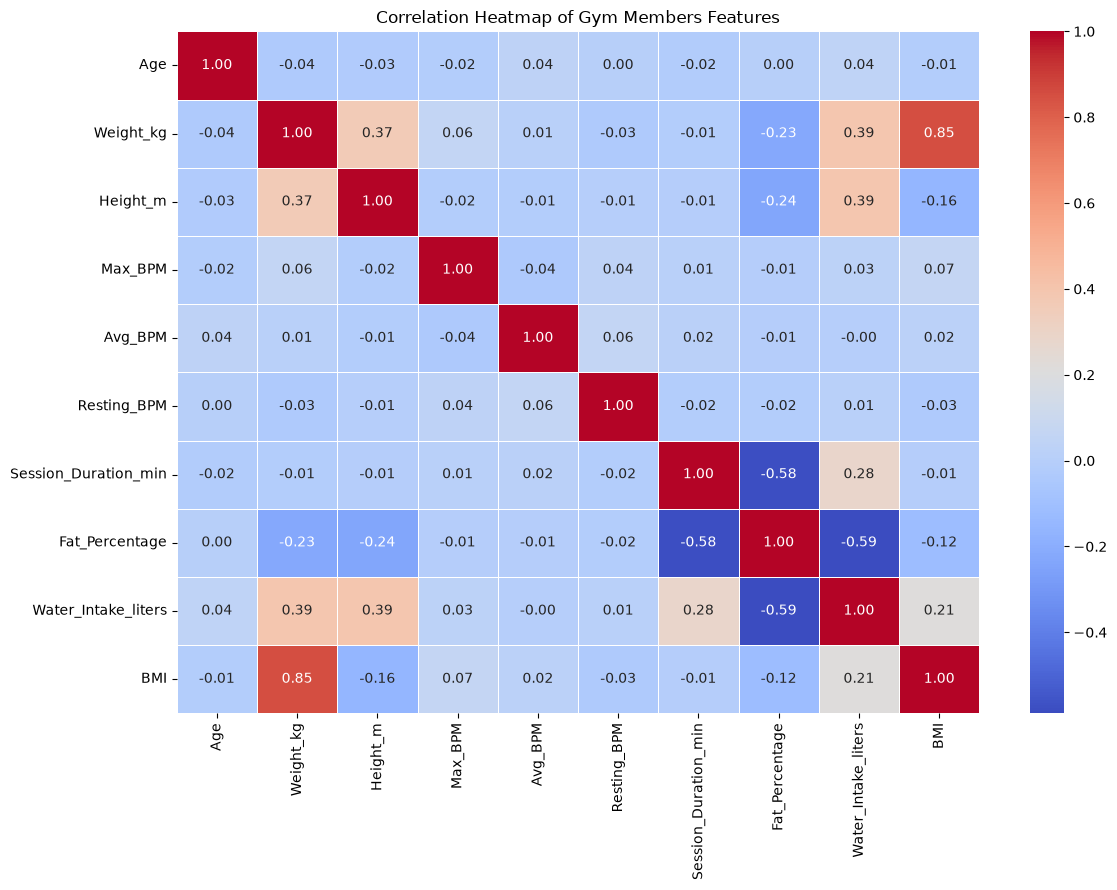

In [16]:
# Stage 1: Correlation Heatmap
 
correlation_matrix = df[FEATURE_COLS].corr()
 
plt.figure(figsize=(12, 9))
 
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
 
plt.title("Correlation Heatmap of Gym Members Features")
plt.tight_layout()
plt.savefig("plots/correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

In [7]:
# Correlation Analysis
 
print("Strongest Positive Correlation:")
print("Weight_kg and BMI: 0.85")
 
print("\nStrongest Negative Correlation:")
print("Fat_Percentage and Water_Intake_liters: -0.59")
 
print("\nOther Important Correlations:")
print("Session_Duration_min and Fat_Percentage: -0.58")
print("Height_m and Water_Intake_liters: 0.39")
print("Weight_kg and Height_m: 0.37")

Strongest Positive Correlation:
Weight_kg and BMI: 0.85

Strongest Negative Correlation:
Fat_Percentage and Water_Intake_liters: -0.59

Other Important Correlations:
Session_Duration_min and Fat_Percentage: -0.58
Height_m and Water_Intake_liters: 0.39
Weight_kg and Height_m: 0.37


In [8]:
# Stage 2: Feature Scaling
 
scaler = StandardScaler()
 
Xtr_scaled = scaler.fit_transform(Xtr)
 
Xte_scaled = scaler.transform(Xte)
 
print("Training data scaled:", Xtr_scaled.shape)
print("Testing data scaled:", Xte_scaled.shape)

Training data scaled: (778, 10)
Testing data scaled: (195, 10)


In [9]:
# Stage 3: Principal Component Analysis (PCA)
 
pca = PCA()
 
Xtr_pca = pca.fit_transform(Xtr_scaled)
 
Xte_pca = pca.transform(Xte_scaled)
 
print("Training PCA shape:", Xtr_pca.shape)
print("Testing PCA shape:", Xte_pca.shape)
 

Training PCA shape: (778, 10)
Testing PCA shape: (195, 10)


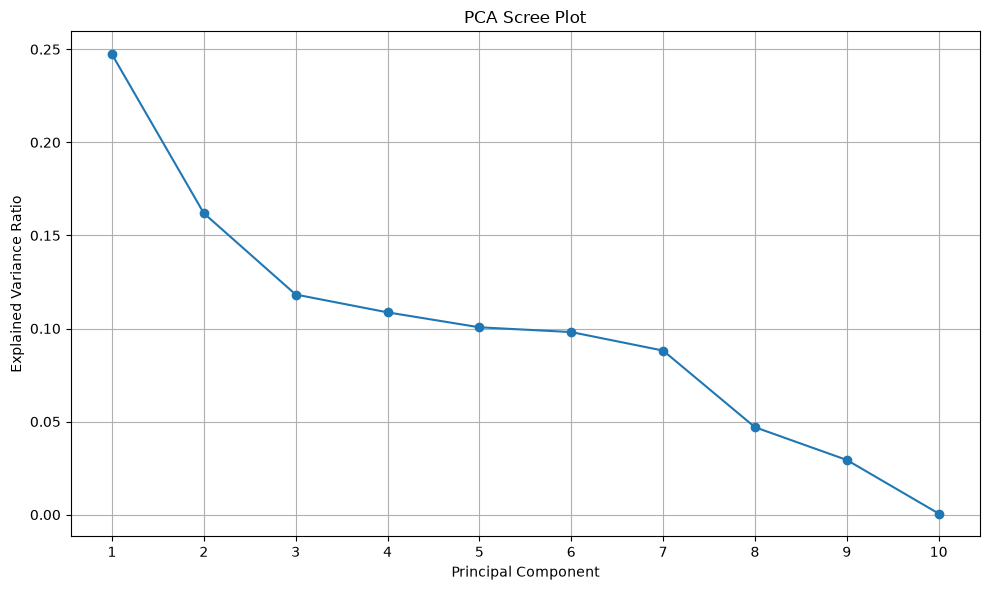

In [17]:
# Stage 4: Scree Plot
 
explained_variance = pca.explained_variance_ratio_
 
plt.figure(figsize=(10, 6))
 
plt.plot(
    range(1, len(explained_variance) + 1),
    explained_variance,
    marker="o"
)
 
plt.title("PCA Scree Plot")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.xticks(range(1, len(explained_variance) + 1))
plt.grid(True)
plt.tight_layout()
plt.savefig("plots/pca_scree_plot.png", dpi=300, bbox_inches="tight")
plt.show()

In [11]:
# Stage 5: Cumulative Explained Variance
 
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
 
for i, variance in enumerate(cumulative_variance, start=1):
    print(f"PC{i}: {variance:.2%}")
 
print("\nFirst 2 Components:", f"{cumulative_variance[1]:.2%}")
print("First 3 Components:", f"{cumulative_variance[2]:.2%}")
 

PC1: 24.73%
PC2: 40.92%
PC3: 52.75%
PC4: 63.62%
PC5: 73.68%
PC6: 83.49%
PC7: 92.30%
PC8: 97.00%
PC9: 99.94%
PC10: 100.00%

First 2 Components: 40.92%
First 3 Components: 52.75%


In [12]:
# Stage 6: PCA Component Loadings
 
loadings = pd.DataFrame(
    pca.components_[:2].T,
    index=FEATURE_COLS,
    columns=["PC1", "PC2"]
)
 
print("PCA Loadings:")
display(loadings)

PCA Loadings:


,PC1,PC2
Age,-0.038704,-0.021111
Weight_kg,0.486148,0.474466
Height_m,0.280862,-0.165527
Max_BPM,0.041635,0.090851
Avg_BPM,0.015190,0.013974
Resting_BPM,-0.015387,-0.026632
Session_Duration_min,0.282541,-0.454588
Fat_Percentage,-0.462537,0.397181
Water_Intake_liters,0.505852,-0.176603
BMI,0.362521,0.585053


In [13]:
# PCA Loadings Interpretation
 
print("PC1: Mainly influenced by Water Intake, Weight, Fat Percentage, and BMI.")
 
print("\nPC2: Mainly influenced by BMI, Weight, Session Duration, and Fat Percentage.")
 

PC1: Mainly influenced by Water Intake, Weight, Fat Percentage, and BMI.

PC2: Mainly influenced by BMI, Weight, Session Duration, and Fat Percentage.


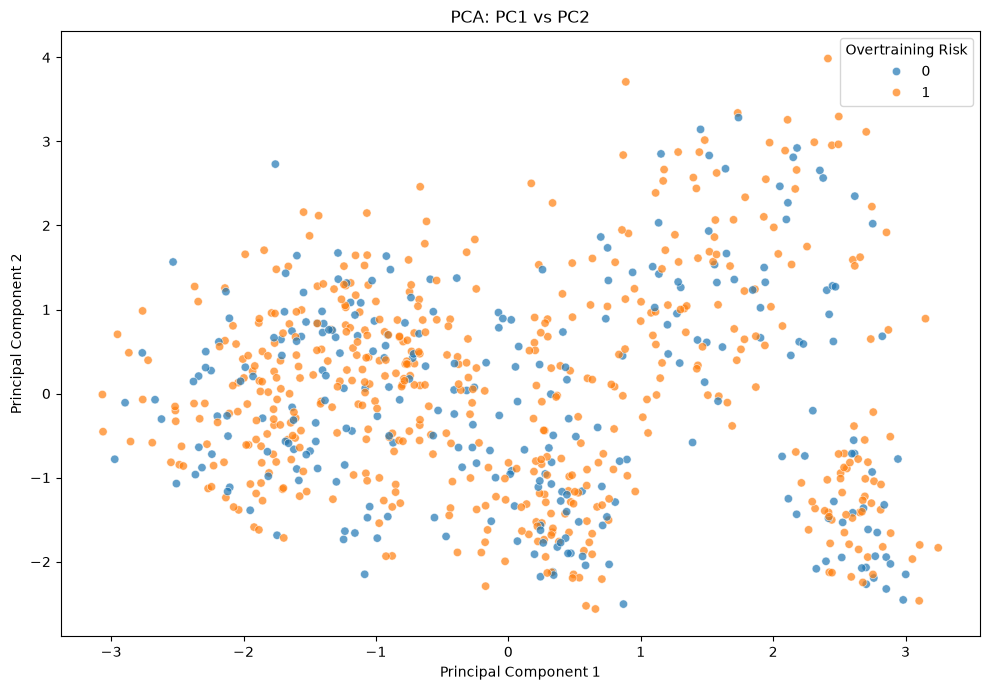

In [18]:
# Stage 7: PC1 vs PC2 Scatter Plot
 
pca_scatter = pd.DataFrame({
    "PC1": Xtr_pca[:, 0],
    "PC2": Xtr_pca[:, 1],
    "Overtraining_Risk_Label": yc_tr.to_numpy()
})
 
plt.figure(figsize=(10, 7))
 
sns.scatterplot(
    data=pca_scatter,
    x="PC1",
    y="PC2",
    hue="Overtraining_Risk_Label",
    alpha=0.7
)
 
plt.title("PCA: PC1 vs PC2")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Overtraining Risk")
plt.tight_layout()
plt.savefig("plots/pca_scatter_plot.png", dpi=300, bbox_inches="tight")
plt.show()

 

PCA Results Summary
 
1. The dataset contains 10 numerical features that were standardized before applying PCA.
 
2. The StandardScaler was fitted only on the training data to avoid data leakage.
 
3. The first two principal components explain 40.92% of the total variance.
 
4. The first three principal components explain 52.75% of the total variance.
 
5. Reducing the data from 10 features to 3 components simplifies the dataset while retaining 52.75% of its variance, although some information is lost.